# Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Course:** Computer Vision Lab  
**Name:** Osam Sami  
**Registration No:** FA23-BAI-056

## Personal Settings
| Setting | Rule | My value |
|---|---|---|
| Random seed | Last two digits of registration number | 56 |
| HOG cell size | Last digit 6 is even | 8 x 8 |
| SIFT grid size | Last digit 6 is between 5 and 9 | 6 x 6 grid (36 keypoints) |

In [1]:
import io
import time
import urllib.request

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.feature import hog
from skimage import exposure
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

REG_NO = "FA23-BAI-056"
digits = "".join(c for c in REG_NO if c.isdigit())
SEED = int(digits[-2:])
last_digit = int(digits[-1])
HOG_CELL = 8 if last_digit % 2 == 0 else 16
GRID = 4 if last_digit <= 4 else 6

print("Registration number:", REG_NO)
print("Seed:", SEED)
print("HOG cell size:", HOG_CELL, "x", HOG_CELL)
print("SIFT grid:", GRID, "x", GRID, "->", GRID * GRID, "keypoints")

Registration number: FA23-BAI-056
Seed: 56
HOG cell size: 8 x 8
SIFT grid: 6 x 6 -> 36 keypoints


# Q1. Data Setup

In [2]:
import subprocess
import sys

t0 = time.time()
KEYS = ["train_images", "train_labels", "val_images", "val_labels", "test_images", "test_labels"]
URLS = [
    "https://zenodo.org/records/10519652/files/bloodmnist_64.npz?download=1",
    "https://zenodo.org/api/records/10519652/files/bloodmnist_64.npz/content",
]
AGENTS = ["pytorch/vision", "curl/8.5.0", "python-requests/2.32.3"]
store = None

for url in URLS:
    for agent in AGENTS:
        try:
            req = urllib.request.Request(url, headers={"User-Agent": agent})
            raw_bytes = urllib.request.urlopen(req, timeout=300).read()
            npz = np.load(io.BytesIO(raw_bytes))
            store = {k: npz[k] for k in KEYS}
            del raw_bytes, npz
            print("Downloaded directly into RAM using agent:", agent)
            break
        except Exception as e:
            print("Failed:", agent, "|", url[:55], "|", e)
    if store is not None:
        break

if store is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "medmnist"], check=True)
    from medmnist import BloodMNIST
    BloodMNIST(split="train", download=True, size=64, root=".")
    npz = np.load("bloodmnist_64.npz")
    store = {k: npz[k] for k in KEYS}
    del npz
    print("Downloaded with medmnist and loaded once into RAM")

print("Dataset ready in", round(time.time() - t0, 1), "seconds")
for k, v in store.items():
    print(k, v.shape, v.dtype)

Downloaded directly into RAM using agent: pytorch/vision
Dataset ready in 197.7 seconds
train_images (11959, 64, 64, 3) uint8
train_labels (11959, 1) uint8
val_images (1712, 64, 64, 3) uint8
val_labels (1712, 1) uint8
test_images (3421, 64, 64, 3) uint8
test_labels (3421, 1) uint8


In [3]:
CLASS_IDS = [1, 5, 6, 7]
CLASS_NAMES = ["eosinophil", "monocyte", "neutrophil", "platelet"]
N_PER_CLASS = {"train": 100, "val": 30, "test": 30}
rng = np.random.RandomState(SEED)


def take_subset(split, n):
    imgs = store[split + "_images"]
    labs = store[split + "_labels"].ravel()
    xs, ys = [], []
    for new_label, old_label in enumerate(CLASS_IDS):
        idx = np.where(labs == old_label)[0]
        pick = rng.choice(idx, n, replace=False)
        xs.append(imgs[pick])
        ys.append(np.full(n, new_label))
    x = np.concatenate(xs)
    y = np.concatenate(ys)
    order = rng.permutation(len(y))
    return x[order], y[order]


raw_train, y_train = take_subset("train", N_PER_CLASS["train"])
raw_val, y_val = take_subset("val", N_PER_CLASS["val"])
raw_test, y_test = take_subset("test", N_PER_CLASS["test"])

for name, x, y in [("train", raw_train, y_train), ("val", raw_val, y_val), ("test", raw_test, y_test)]:
    print(name, "images:", x.shape, "labels:", y.shape)
    for c, cname in enumerate(CLASS_NAMES):
        print("   ", cname, ":", int((y == c).sum()))

train images: (400, 64, 64, 3) labels: (400,)
    eosinophil : 100
    monocyte : 100
    neutrophil : 100
    platelet : 100
val images: (120, 64, 64, 3) labels: (120,)
    eosinophil : 30
    monocyte : 30
    neutrophil : 30
    platelet : 30
test images: (120, 64, 64, 3) labels: (120,)
    eosinophil : 30
    monocyte : 30
    neutrophil : 30
    platelet : 30


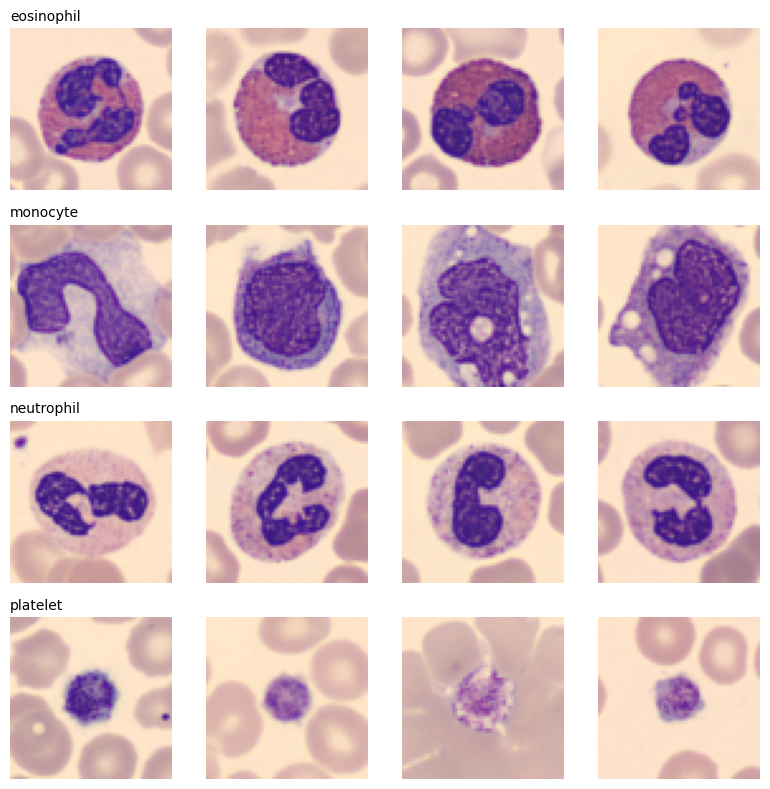

In [4]:
fig, axes = plt.subplots(len(CLASS_NAMES), 4, figsize=(8, 8))
for c, cname in enumerate(CLASS_NAMES):
    idx = np.where(y_train == c)[0][:4]
    for j, i in enumerate(idx):
        axes[c, j].imshow(raw_train[i])
        axes[c, j].axis("off")
        if j == 0:
            axes[c, j].set_title(cname, loc="left", fontsize=10)
plt.tight_layout()
plt.savefig("q1_example_grid.png", dpi=150)
plt.show()

In [5]:
def prep(x):
    return np.stack([cv2.resize(cv2.cvtColor(i, cv2.COLOR_RGB2GRAY), (128, 128), interpolation=cv2.INTER_LINEAR) for i in x])


X_train = prep(raw_train)
X_val = prep(raw_val)
X_test = prep(raw_test)
print("Prepared grayscale shapes:", X_train.shape, X_val.shape, X_test.shape, X_train.dtype)

Prepared grayscale shapes: (400, 128, 128) (120, 128, 128) (120, 128, 128) uint8


# Q2. HOG + SVM

## Q2.1 HOG Feature Length (hand calculation)
My settings: image 128 x 128, cell size 8 x 8, 9 orientations, block = 2 x 2 cells, block stride = 1 cell.

- Cells per side = 128 / 8 = 16, so the image has 16 x 16 cells.
- Blocks per side = 16 - 2 + 1 = 15, so the image has 15 x 15 = 225 blocks.
- Each block holds 2 x 2 cells x 9 orientations = 36 values.
- Total feature length = 225 x 36 = **8100**.

In [6]:
def hog_feat(img):
    return hog(img, orientations=9, pixels_per_cell=(HOG_CELL, HOG_CELL), cells_per_block=(2, 2), block_norm="L2-Hys", feature_vector=True)


def hog_all(X):
    return np.array([hog_feat(i) for i in X], dtype=np.float32)


t0 = time.time()
H_train = hog_all(X_train)
H_val = hog_all(X_val)
print("HOG feature length from code:", H_train.shape[1])

cells_per_side = 128 // HOG_CELL
blocks_per_side = cells_per_side - 1
manual_length = blocks_per_side * blocks_per_side * 2 * 2 * 9
print("HOG feature length by hand:", manual_length)
print("Match:", manual_length == H_train.shape[1])
print("Train matrix:", H_train.shape, "Val matrix:", H_val.shape)
print("Time:", round(time.time() - t0, 1), "seconds")

HOG feature length from code: 8100
HOG feature length by hand: 8100
Match: True
Train matrix: (400, 8100) Val matrix: (120, 8100)
Time: 3.3 seconds


## Q2.2 HOG Pictures (one image per class)

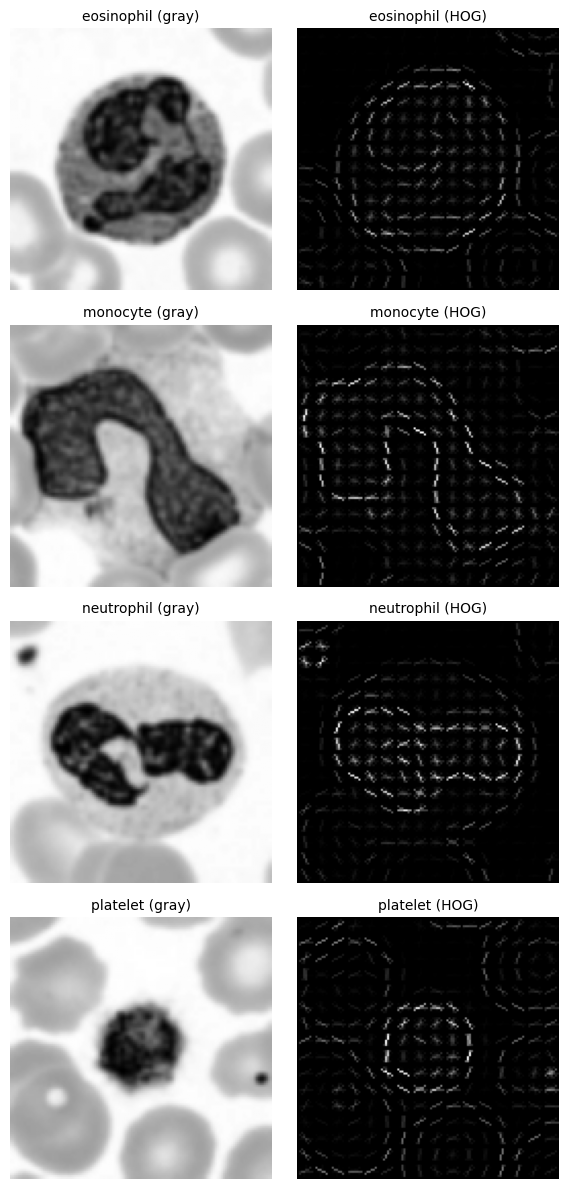

In [7]:
fig, axes = plt.subplots(len(CLASS_NAMES), 2, figsize=(6, 12))
for c, cname in enumerate(CLASS_NAMES):
    i = np.where(y_train == c)[0][0]
    _, hog_img = hog(X_train[i], orientations=9, pixels_per_cell=(HOG_CELL, HOG_CELL), cells_per_block=(2, 2), block_norm="L2-Hys", visualize=True)
    hog_img = exposure.rescale_intensity(hog_img, in_range=(0, hog_img.max() + 1e-9))
    axes[c, 0].imshow(X_train[i], cmap="gray")
    axes[c, 0].set_title(cname + " (gray)", fontsize=10)
    axes[c, 0].axis("off")
    axes[c, 1].imshow(hog_img, cmap="gray")
    axes[c, 1].set_title(cname + " (HOG)", fontsize=10)
    axes[c, 1].axis("off")
plt.tight_layout()
plt.savefig("q2_hog_pictures.png", dpi=150)
plt.show()

## Q2.3 Train HOG + SVM (C chosen on validation set)

   C  val_accuracy
 0.1         0.725
 1.0         0.725
10.0         0.725
Best C for HOG: 0.1
HOG + SVM validation confusion matrix
Validation accuracy: 0.725
Validation macro-F1: 0.7166
Confusion matrix (rows = true, cols = predicted):
[[13  7  8  2]
 [ 5 22  3  0]
 [ 5  3 22  0]
 [ 0  0  0 30]]


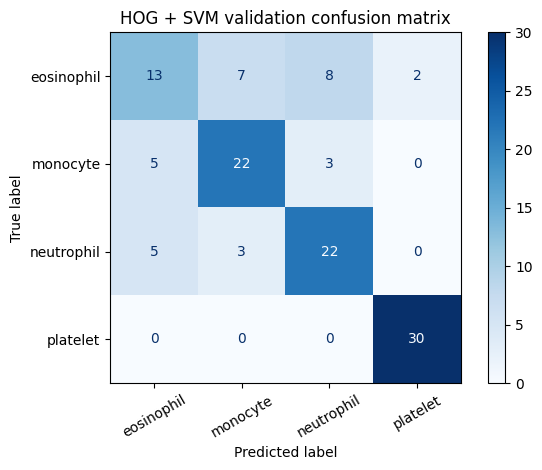

In [8]:
C_GRID = [0.1, 1, 10]


def fit_select_C(Xtr, ytr, Xva, yva):
    best = None
    rows = []
    for C in C_GRID:
        model = LinearSVC(C=C, max_iter=5000, random_state=SEED).fit(Xtr, ytr)
        acc = accuracy_score(yva, model.predict(Xva))
        rows.append({"C": C, "val_accuracy": round(acc, 4)})
        if best is None or acc > best[1]:
            best = (C, acc, model)
    return best, pd.DataFrame(rows)


def report(model, Xva, yva, title, fname):
    pred = model.predict(Xva)
    acc = accuracy_score(yva, pred)
    f1 = f1_score(yva, pred, average="macro")
    cm = confusion_matrix(yva, pred)
    print(title)
    print("Validation accuracy:", round(acc, 4))
    print("Validation macro-F1:", round(f1, 4))
    print("Confusion matrix (rows = true, cols = predicted):")
    print(cm)
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(cmap="Blues", xticks_rotation=30)
    plt.title(title)
    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    plt.show()
    return acc, f1, cm


(best_C_hog, _, hog_model), hog_c_table = fit_select_C(H_train, y_train, H_val, y_val)
print(hog_c_table.to_string(index=False))
print("Best C for HOG:", best_C_hog)
hog_val_acc, hog_val_f1, cm_hog = report(hog_model, H_val, y_val, "HOG + SVM validation confusion matrix", "q2_hog_confusion_matrix.png")

# Q3. SIFT + SVM

## Q3.1 Normal SIFT Detection

In [9]:
sift = cv2.SIFT_create()
kp_counts = []
kp_store = []
for img in X_train:
    kps, _ = sift.detectAndCompute(img, None)
    kp_counts.append(len(kps))
    kp_store.append(kps)
kp_counts = np.array(kp_counts)

print("Average keypoints per image:", round(kp_counts.mean(), 2))
print("Minimum keypoints per image:", int(kp_counts.min()))
print("Maximum keypoints per image:", int(kp_counts.max()))
print("Images with zero keypoints:", int((kp_counts == 0).sum()), "out of", len(kp_counts))

Average keypoints per image: 72.28
Minimum keypoints per image: 10
Maximum keypoints per image: 177
Images with zero keypoints: 0 out of 400


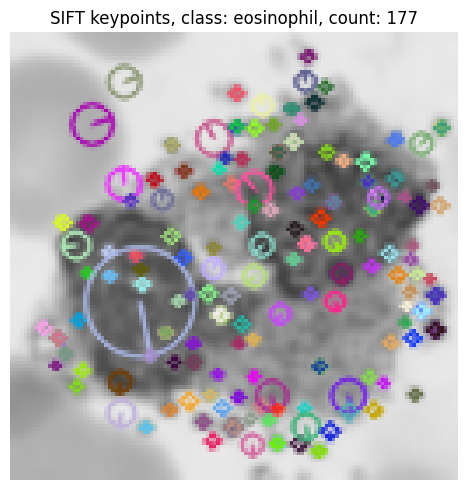

In [10]:
show_i = int(np.argmax(kp_counts))
vis = cv2.drawKeypoints(X_train[show_i], kp_store[show_i], None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title("SIFT keypoints, class: " + CLASS_NAMES[y_train[show_i]] + ", count: " + str(kp_counts[show_i]))
plt.axis("off")
plt.tight_layout()
plt.savefig("q3_sift_keypoints.png", dpi=150)
plt.show()

**Why a different keypoint count is a problem for an SVM:** SVM needs every image to be a feature vector of the same fixed length, but normal SIFT gives a different number of 128-dimensional descriptors for each image (and sometimes none), so the descriptors cannot be joined into one equal-length vector.

## Q3.2 Fixed Grid SIFT Features (hand calculation)
My settings: 6 x 6 grid on the 128 x 128 image, keypoint size 32, SIFT descriptor length 128.

- Grid points = 6 x 6 = 36 keypoints.
- Each keypoint gives one 128-dimensional descriptor.
- Total feature length = 36 x 128 = **4608**.

In [11]:
step = 128 / GRID
GRID_PTS = [(step * (j + 0.5), step * (i + 0.5)) for i in range(GRID) for j in range(GRID)]


def sift_feat(img):
    kps = [cv2.KeyPoint(float(x), float(y), 32) for x, y in GRID_PTS]
    _, desc = sift.compute(img, kps)
    return desc.reshape(-1) / 512.0


def sift_all(X):
    return np.array([sift_feat(i) for i in X], dtype=np.float32)


t0 = time.time()
S_train = sift_all(X_train)
S_val = sift_all(X_val)
print("Grid points:", len(GRID_PTS))
print("SIFT feature length from code:", S_train.shape[1])
print("SIFT feature length by hand:", GRID * GRID * 128)
print("Match:", GRID * GRID * 128 == S_train.shape[1])
print("Train matrix:", S_train.shape, "Val matrix:", S_val.shape)
print("Time:", round(time.time() - t0, 1), "seconds")

Grid points: 36
SIFT feature length from code: 4608
SIFT feature length by hand: 4608
Match: True
Train matrix: (400, 4608) Val matrix: (120, 4608)
Time: 7.7 seconds


## Q3.3 Train SIFT + SVM (C chosen on validation set)

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


   C  val_accuracy
 0.1        0.8417
 1.0        0.8500
10.0        0.8083
Best C for SIFT: 1
SIFT + SVM validation confusion matrix
Validation accuracy: 0.85
Validation macro-F1: 0.84
Confusion matrix (rows = true, cols = predicted):
[[16  8  4  2]
 [ 2 28  0  0]
 [ 1  1 28  0]
 [ 0  0  0 30]]


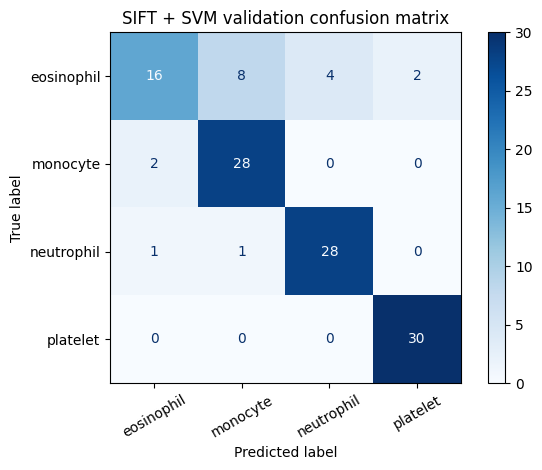

In [12]:
(best_C_sift, _, sift_model), sift_c_table = fit_select_C(S_train, y_train, S_val, y_val)
print(sift_c_table.to_string(index=False))
print("Best C for SIFT:", best_C_sift)
sift_val_acc, sift_val_f1, cm_sift = report(sift_model, S_val, y_val, "SIFT + SVM validation confusion matrix", "q3_sift_confusion_matrix.png")

# Q4. Robustness

## Q4.1 Prediction (written before running the test)
- **Rotation:** I think HOG will lose more accuracy. HOG stores gradient orientation histograms in fixed cell positions, so a 20 degree rotation moves edges to different orientation bins and different cells. The grid SIFT descriptors are also not rotation invariant here, but each one covers a larger 32 x 32 patch with smoothing, so I expect a smaller drop.
- **Noise:** I think HOG will lose more accuracy. HOG uses raw pixel gradients, and noise adds many random small gradients. SIFT blurs the patch with a Gaussian window before building the histograms, so it should handle noise better.

## Q4.2 Evaluation on the Test Set (models frozen)

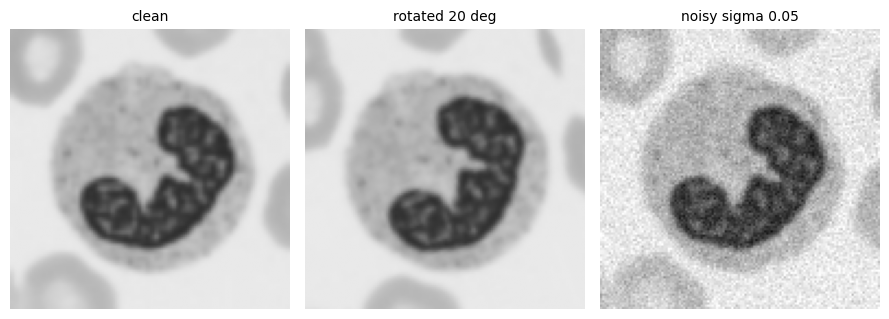

In [13]:
def rotate20(img):
    M = cv2.getRotationMatrix2D((64, 64), 20, 1.0)
    return cv2.warpAffine(img, M, (128, 128), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)


def add_noise(X, seed):
    r = np.random.RandomState(seed)
    f = X.astype(np.float32) / 255.0
    f = np.clip(f + r.normal(0, 0.05, f.shape), 0, 1)
    return (f * 255).round().astype(np.uint8)


X_test_rot = np.stack([rotate20(i) for i in X_test])
X_test_noisy = add_noise(X_test, SEED)

fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))
for ax, im, t in zip(axes, [X_test[0], X_test_rot[0], X_test_noisy[0]], ["clean", "rotated 20 deg", "noisy sigma 0.05"]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(t, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.savefig("q4_test_variants.png", dpi=150)
plt.show()

In [14]:
test_sets = {"Clean": X_test, "Rotated": X_test_rot, "Noisy": X_test_noisy}
results = {"HOG + SVM": {}, "SIFT + SVM": {}}
t0 = time.time()
for case, Xc in test_sets.items():
    results["HOG + SVM"][case] = accuracy_score(y_test, hog_model.predict(hog_all(Xc)))
    results["SIFT + SVM"][case] = accuracy_score(y_test, sift_model.predict(sift_all(Xc)))

table = pd.DataFrame(results).T
table.columns = ["Clean accuracy", "Rotated accuracy", "Noisy accuracy"]
table.index.name = "Model"
table["Drop under rotation"] = table["Clean accuracy"] - table["Rotated accuracy"]
table["Drop under noise"] = table["Clean accuracy"] - table["Noisy accuracy"]
print(table.round(4).to_string())
table.round(4).to_csv("q4_results.csv")
print("Time:", round(time.time() - t0, 1), "seconds")

            Clean accuracy  Rotated accuracy  Noisy accuracy  Drop under rotation  Drop under noise
Model                                                                                              
HOG + SVM           0.7000            0.6917          0.4000               0.0083               0.3
SIFT + SVM          0.7917            0.8500          0.7917              -0.0583               0.0
Time: 7.5 seconds


## Q4.3 Was My Prediction Correct?
_My prediction was correct for noise and, in direction, for rotation. Under noise HOG fell from 0.7000 to 0.4000 (a drop of 0.3000) while SIFT stayed at 0.7917, so HOG lost much more. Under rotation HOG dropped only from 0.7000 to 0.6917 while SIFT actually rose from 0.7917 to 0.8500, so HOG lost more, but the rotation change is small for both models (about 1 and 7 images out of 120), so I cannot say from this table that 20 degrees really hurt either model._

# Q5. Short Answers and AI Log

## Q5.1 Short Answers
**(a) Why does HOG use block normalisation?**  
Gradient strength changes with local lighting and contrast, for example because of different stain intensity in blood-cell images. HOG groups cells into overlapping blocks and normalises the histogram of each block, so the features depend on the shape and edge direction and not on how bright or contrasty the image is.

**(b) Why is it wrong to choose C using the test set?**  
If C is picked by looking at test accuracy, the test set has influenced the model, so it is no longer unseen data and the reported accuracy becomes too optimistic. The validation set should be used for choosing C, and the test set should be used once at the end for an honest estimate.

## Q5.2 Most Confused Classes

In [15]:
def top_confused_pair(cm):
    best_pair, best_count = None, -1
    for i in range(len(cm)):
        for j in range(i + 1, len(cm)):
            count = cm[i, j] + cm[j, i]
            if count > best_count:
                best_pair, best_count = (i, j), int(count)
    return best_pair, best_count


for name, cm in [("HOG + SVM", cm_hog), ("SIFT + SVM", cm_sift)]:
    (i, j), count = top_confused_pair(cm)
    print(name, "most confused pair:", CLASS_NAMES[i], "and", CLASS_NAMES[j], "| total mistakes between them:", count)
    print("   ", CLASS_NAMES[i], "predicted as", CLASS_NAMES[j], ":", int(cm[i, j]))
    print("   ", CLASS_NAMES[j], "predicted as", CLASS_NAMES[i], ":", int(cm[j, i]))

HOG + SVM most confused pair: eosinophil and neutrophil | total mistakes between them: 13
    eosinophil predicted as neutrophil : 8
    neutrophil predicted as eosinophil : 5
SIFT + SVM most confused pair: eosinophil and monocyte | total mistakes between them: 10
    eosinophil predicted as monocyte : 8
    monocyte predicted as eosinophil : 2


_HOG confused eosinophil and neutrophil most (13 mistakes) and SIFT confused eosinophil and monocyte most (10 mistakes). Eosinophil is the weakest class for both models (13 of 30 correct for HOG, 16 of 30 for SIFT). In the colour images an eosinophil has red-pink cytoplasm, but after grayscale conversion this colour becomes a normal gray, so only the nucleus shape and size are left, and these look similar in eosinophils, neutrophils and monocytes._

## Q5.3 AI Log
| Prompt (one line) | What I changed | How I checked the result |
|---|---|---|
| Make a CPU-only HOG + SVM vs SIFT + SVM notebook for BloodMNIST using my reg no FA23-BAI-056. Then: download cell gives HTTP Error 403, fix it. | Added my own rules (dataset from direct link, kept in RAM, CPU only). Replaced the Zenodo download cell with a fallback one. Saved figures in my assets folder. | Re-ran in Colab, checked printed settings and shapes. Matched HOG 8100 and SIFT 4608 with my hand calculation. Each confusion matrix row adds to 30. |